# 01 — Explore OSM data



### Download a small real area from OpenStreetMap

Using `osmnx` to pull a tiny area (Ken Sturgeon Park) and build it into a real graph (`network_type="walk"` since this project cares about walking/accessibility, not driving). Then checking its basic size: number of nodes (intersections/points) and edges (path segments).

In [1]:
import osmnx as ox
import matplotlib

# Stands for Graph
G = ox.graph_from_place("Ken Sturgeon Park, Newmarket, Canada", network_type="walk")


print(G.number_of_nodes())
print(G.number_of_edges())




9
22


### Visualize the graph

Plotting `G` to see the actual shape of the park's paths — a sanity check that the graph really matches real-world geography, not just numbers.

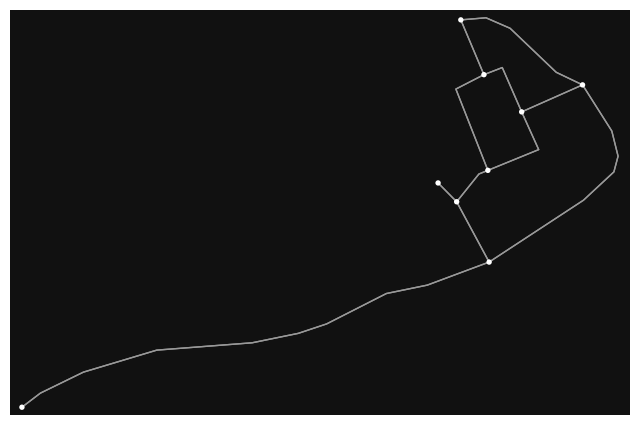

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [2]:
ox.plot_graph(G)

### Inspect what data each edge actually has

Looping through every edge and printing its attributes (`length`, `highway` type, etc.) to see what osmnx gives us by default — this is where I first noticed `wheelchair`/`surface` tags were nowhere to be found.

In [3]:
for u, v, data in G.edges(data=True):
    print(u, "->", v, data)

1034838611 -> 13143725493 {'osmid': 89183907, 'highway': 'path', 'oneway': False, 'reversed': True, 'length': np.float64(28.010380306147365)}
1034838611 -> 1034838722 {'osmid': 1246984801, 'highway': 'path', 'oneway': False, 'reversed': False, 'length': np.float64(102.7522411227296), 'geometry': <LINESTRING (-79.431 44.033, -79.43 44.034, -79.43 44.034, -79.43 44.034, -7...>}
1034838611 -> 1034838637 {'osmid': 1246984801, 'highway': 'path', 'oneway': False, 'reversed': True, 'length': np.float64(202.51334106825837), 'geometry': <LINESTRING (-79.431 44.033, -79.431 44.033, -79.431 44.033, -79.432 44.033,...>}
1034838633 -> 13143725488 {'osmid': 89183906, 'highway': 'path', 'oneway': False, 'reversed': True, 'length': np.float64(24.316748763669064)}
1034838633 -> 1034838722 {'osmid': 1246984801, 'highway': 'path', 'oneway': False, 'reversed': True, 'length': np.float64(59.094621545599786), 'geometry': <LINESTRING (-79.431 44.034, -79.431 44.034, -79.431 44.034, -79.431 44.034,...>}
10348

### Fix: tell osmnx to keep accessibility tags, then try a bigger urban area

osmnx filters OSM tags through a whitelist by default, and `wheelchair`/`surface`/`kerb`/`crossing`/`tactile_paving` aren't in it — so it was silently dropping them. Expanding `useful_tags_way` and `useful_tags_node` before downloading fixes that. Also switching to a denser, more central area (Financial District, Toronto) since a tiny park is unlikely to have much accessibility tagging at all.

In [ ]:
ox.settings.useful_tags_way += ["wheelchair", "surface"]
ox.settings.useful_tags_node += ["kerb", "crossing", "tactile_paving"]

G2 = ox.graph_from_place("Financial District, Toronto, Canada", network_type="walk")

print(G2.number_of_nodes())
print(G2.number_of_edges())


834
2372
394497106 {'y': 43.647889, 'x': -79.3834271, 'kerb': 'lowered', 'street_count': 4}
469107103 {'y': 43.6482565, 'x': -79.3849903, 'kerb': 'lowered', 'street_count': 3}
780794971 {'y': 43.6451936, 'x': -79.3834758, 'highway': 'crossing', 'crossing': 'uncontrolled', 'street_count': 3}
10670723113 {'y': 43.6484957, 'x': -79.3843397, 'highway': 'crossing', 'crossing': 'unmarked', 'street_count': 4}


### Visualize the bigger area

Same sanity check as before, now on the real downtown street grid.

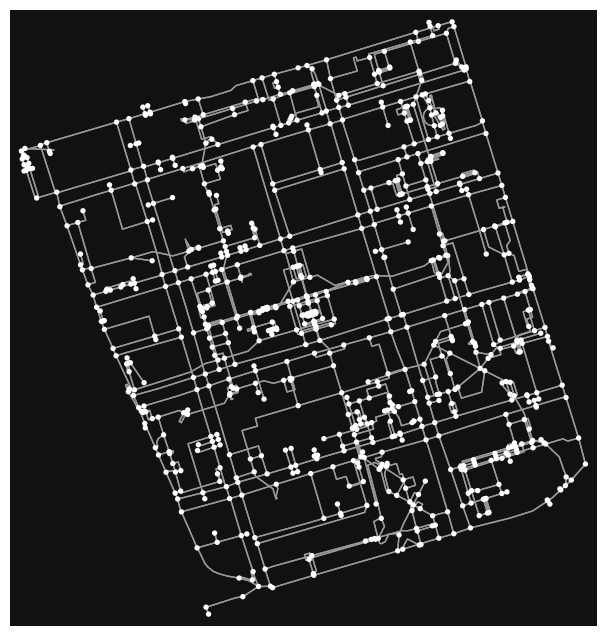

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [8]:
ox.plot_graph(G2)

### Check for real accessibility tags on nodes

Now that the whitelist is fixed, checking every node for `kerb`, `crossing`, `tactile_paving` tags. This found 4 nodes with genuine tags (2 curb ramps, 2 marked/unmarked crossings) out of 834 nodes total.

**Correction:** this only re-checked nodes. Re-running the same check on edges for `wheelchair`/`surface` (after the fix, not before) shows a much fuller picture: `surface` is present on the large majority of footway/service edges, and `wheelchair` is present directly on ~20 edges (`yes`/`designated`). The earlier "coverage is ~0.5%" conclusion was based on an incomplete re-test — see `notes/01-graphs-and-shortest-path.md` for the full correction.

In [ ]:
for node_id, data in G2.nodes(data=True):
    if "kerb" in data or "crossing" in data or "tactile_paving" in data:
        print(node_id, data)


for u, v, data in G2.edges(data=True):
    if "wheelchair" in data or "surface" in data:
        print(u, "->", v, data)

394497106 {'y': 43.647889, 'x': -79.3834271, 'kerb': 'lowered', 'street_count': 4}
469107103 {'y': 43.6482565, 'x': -79.3849903, 'kerb': 'lowered', 'street_count': 3}
780794971 {'y': 43.6451936, 'x': -79.3834758, 'highway': 'crossing', 'crossing': 'uncontrolled', 'street_count': 3}
10670723113 {'y': 43.6484957, 'x': -79.3843397, 'highway': 'crossing', 'crossing': 'unmarked', 'street_count': 4}
